# 00_data_reproducibility

**Objective:** Data audit, features, target, cohort and splitting

**Status:** In development


In [2]:
# ==================================================
# 00A.1 — Dataset Loading and Initial Verification
# ==================================================

from pathlib import Path
import json
import polars as pl
from IPython.display import display

# 1. Locate project root
ROOT = next(
    (
        p for p in [Path.cwd(), Path.cwd().parent]
        if (p / "configs" / "project.json").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Open this notebook "
        "inside lendingclub_project/notebooks."
    )

# 2. Read configuration
with open(ROOT / "configs/project.json", "r") as f:
    config = json.load(f)

DATA_PATH = Path(config["raw_data_path"])

if not DATA_PATH.is_absolute():
    DATA_PATH = ROOT / DATA_PATH

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check raw_data_path in configs/project.json."
    )

# 3. Load Feather lazily
lf = pl.scan_ipc(str(DATA_PATH))

# 4. Dataset information
schema = lf.collect_schema()
columns = schema.names()

n_rows = lf.select(pl.len()).collect().item()
n_cols = len(columns)

print("=" * 55)
print("LENDINGCLUB — DATASET OVERVIEW")
print("=" * 55)

print(f"File       : {DATA_PATH.name}")
print(f"Rows       : {n_rows:,}")
print(f"Columns    : {n_cols}")
print(f"File size  : {DATA_PATH.stat().st_size / 1024**2:.2f} MiB")
print(f"Polars     : {pl.__version__}")

# 5. Schema
schema_df = pl.DataFrame({
    "feature": columns,
    "dtype": [str(schema[c]) for c in columns]
})

print("\nDATA TYPE DISTRIBUTION")
display(
    schema_df.group_by("dtype")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
)

print("\nESSENTIAL COLUMNS")
important_cols = [
    "id",
    "issue_d",
    "loan_status",
    "term",
    "loan_amnt",
    "annual_inc",
    "dti",
    "fico_range_low",
    "fico_range_high",
]

display(
    schema_df.filter(
        pl.col("feature").is_in(important_cols)
    )
)

print("\nALL COLUMN NAMES")
print(columns)

# 6. Save schema report
audit_dir = ROOT / "reports" / "audits"
audit_dir.mkdir(parents=True, exist_ok=True)

schema_df.write_csv(
    audit_dir / "00_schema.csv"
)

print("\nSchema saved successfully.")

LENDINGCLUB — DATASET OVERVIEW
File       : lending_club_2020_q3.feather
Rows       : 2,925,492
Columns    : 141
File size  : 545.27 MiB
Polars     : 2.1.0

DATA TYPE DISTRIBUTION


dtype,count
str,u32
"""Int16""",54
"""Float32""",26
"""Categorical""",22
"""Int64""",15
"""Int32""",15
"""Datetime(time_unit='ns', time_…",9



ESSENTIAL COLUMNS


feature,dtype
str,str
"""id""","""Int64"""
"""loan_amnt""","""Int32"""
"""term""","""Int16"""
"""annual_inc""","""Float32"""
"""issue_d""","""Datetime(time_unit='ns', time_…"
"""loan_status""","""Categorical"""
"""dti""","""Float32"""
"""fico_range_low""","""Int32"""
"""fico_range_high""","""Int32"""



ALL COLUMN NAMES
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 't

In [30]:
# =====================================================
# 00A.2 — Complete Missing Value Audit
# =====================================================

BATCH_SIZE = 15

def collect_safe(query):
    try:
        return query.collect(engine="streaming")
    except TypeError:
        return query.collect(streaming=True)


def audit_batch(batch):
    expressions = []

    for i, col in enumerate(batch):
        expressions.append(
            pl.col(col).is_null().sum().alias(f"null_{i}")
        )

        if schema[col] in (pl.Float32, pl.Float64):
            expressions.append(
                pl.col(col).is_nan().sum().alias(f"nan_{i}")
            )

    result = collect_safe(
        lf.select(expressions)
    ).row(0, named=True)

    return [
        {
            "feature": col,
            "dtype": str(schema[col]),
            "null_count": int(result[f"null_{i}"]),
            "nan_count": int(result.get(f"nan_{i}", 0)),
            "audit_error": None
        }
        for i, col in enumerate(batch)
    ]


results = []

for start in range(0, len(columns), BATCH_SIZE):
    batch = columns[start:start + BATCH_SIZE]

    try:
        results.extend(audit_batch(batch))

    except Exception:
        # Identify problematic columns individually
        for col in batch:
            try:
                results.extend(audit_batch([col]))
            except Exception as exc:
                results.append({
                    "feature": col,
                    "dtype": str(schema[col]),
                    "null_count": None,
                    "nan_count": None,
                    "audit_error": str(exc)[:300]
                })

    print(
        f"Audited {min(start + BATCH_SIZE, len(columns))}"
        f"/{len(columns)} columns"
    )


missing_df = (
    pl.DataFrame(results)
    .with_columns(
        (
            pl.col("null_count") + pl.col("nan_count")
        ).alias("missing_count")
    )
    .with_columns(
        (
            100 * pl.col("missing_count") / n_rows
        ).round(2).alias("missing_pct")
    )
    .sort("missing_pct", descending=True, nulls_last=True)
)

# Summary
print("\n" + "=" * 55)
print("MISSING VALUE AUDIT SUMMARY")
print("=" * 55)

print("Total columns:", len(columns))

print(
    "Columns without missing values:",
    missing_df.filter(pl.col("missing_count") == 0).height
)

print(
    "Columns with >50% missing:",
    missing_df.filter(pl.col("missing_pct") > 50).height
)

print(
    "Columns with >90% missing:",
    missing_df.filter(pl.col("missing_pct") > 90).height
)

print(
    "Completely missing columns:",
    missing_df.filter(pl.col("missing_count") == n_rows).height
)

print(
    "Unreadable columns:",
    missing_df.filter(pl.col("audit_error").is_not_null()).height
)
pl.Config.set_tbl_rows(30)
print("\nTOP 30 COLUMNS BY MISSINGNESS")
display(missing_df.head(30))

print("\nUNREADABLE COLUMNS")
display(
    missing_df.filter(
        pl.col("audit_error").is_not_null()
    )
)

# Save full audit
missing_df.write_csv(
    audit_dir / "00_missing_value_audit.csv"
)

print("\nFull missing-value report saved.")

Audited 15/141 columns
Audited 30/141 columns
Audited 45/141 columns
Audited 60/141 columns
Audited 75/141 columns
Audited 90/141 columns
Audited 105/141 columns
Audited 120/141 columns
Audited 135/141 columns
Audited 141/141 columns

MISSING VALUE AUDIT SUMMARY
Total columns: 141
Columns without missing values: 122
Columns with >50% missing: 5
Columns with >90% missing: 4
Completely missing columns: 0
Unreadable columns: 10

TOP 30 COLUMNS BY MISSINGNESS


feature,dtype,null_count,nan_count,audit_error,missing_count,missing_pct
str,str,i64,i64,str,i64,f64
"""hardship_start_date""","""Datetime(time_unit='ns', time_…",2781854,0,null,2781854,95.09
"""hardship_end_date""","""Datetime(time_unit='ns', time_…",2781854,0,null,2781854,95.09
"""payment_plan_start_date""","""Datetime(time_unit='ns', time_…",2781854,0,null,2781854,95.09
"""sec_app_earliest_cr_line""","""Datetime(time_unit='ns', time_…",2727668,0,null,2727668,93.24
"""next_pymnt_d""","""Datetime(time_unit='ns', time_…",1860331,0,null,1860331,63.59
"""last_pymnt_d""","""Datetime(time_unit='ns', time_…",4921,0,null,4921,0.17
"""revol_util""","""Float32""",2660,0,null,2660,0.09
"""id""","""Int64""",0,0,null,0,0.0
"""loan_amnt""","""Int32""",0,0,null,0,0.0



UNREADABLE COLUMNS


feature,dtype,null_count,nan_count,audit_error,missing_count,missing_pct
str,str,i64,i64,str,i64,f64
"""emp_title""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""emp_length""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""title""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""zip_code""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""verification_status_joint""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""hardship_flag""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""hardship_type""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""hardship_reason""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null
"""hardship_status""","""Categorical""",null,null,"""The dictionary key must fit in…",null,null



Full missing-value report saved.


In [29]:
# ============================================================
# 00A.3 — Placeholder Audit + Categorical Recovery
# LendingClub 2007–2020 Q3
# ============================================================

import gc
import polars as pl
import pyarrow as pa
import pyarrow.feather as feather
import pyarrow.compute as pc

from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

BATCH_SIZE = 12

numeric_types = {
    pl.Int8, pl.Int16, pl.Int32, pl.Int64,
    pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64,
    pl.Float32, pl.Float64
}

text_types = {
    pl.String, pl.Categorical, pl.Enum
}

text_missing_tokens = [
    "null", "nan", "none", "n/a", "missing", "na"
]

numeric_cols = [
    c for c in columns if schema[c] in numeric_types
]

categorical_cols = [
    c for c in columns if schema[c] in text_types
]

print("Numeric columns:", len(numeric_cols))
print("Categorical/text columns:", len(categorical_cols))


# ------------------------------------------------------------
# 2. Numeric placeholder audit
# ------------------------------------------------------------

def audit_numeric_batch(batch):
    """Count suspicious numeric values in a batch of columns."""

    expressions = []

    for i, col in enumerate(batch):
        x = pl.col(col)

        expressions.extend([
            (x == -1).fill_null(False)
            .sum().alias(f"minus1_{i}"),

            (x == -999).fill_null(False)
            .sum().alias(f"minus999_{i}"),

            (x == 0).fill_null(False)
            .sum().alias(f"zero_{i}")
        ])

    result = lf.select(expressions).collect(
        engine="streaming"
    ).row(0, named=True)

    return [
        {
            "feature": col,
            "dtype": str(schema[col]),
            "minus_one_count": int(result[f"minus1_{i}"]),
            "minus_999_count": int(result[f"minus999_{i}"]),
            "zero_count": int(result[f"zero_{i}"]),
            "blank_count": None,
            "text_missing_count": None,
            "audit_error": None
        }
        for i, col in enumerate(batch)
    ]


placeholder_rows = []

for start in range(0, len(numeric_cols), BATCH_SIZE):

    batch = numeric_cols[start:start + BATCH_SIZE]

    try:
        placeholder_rows.extend(
            audit_numeric_batch(batch)
        )

    except Exception:
        # If a batch fails, check each column separately.
        for col in batch:
            try:
                placeholder_rows.extend(
                    audit_numeric_batch([col])
                )

            except Exception as exc:
                placeholder_rows.append({
                    "feature": col,
                    "dtype": str(schema[col]),
                    "minus_one_count": None,
                    "minus_999_count": None,
                    "zero_count": None,
                    "blank_count": None,
                    "text_missing_count": None,
                    "audit_error": str(exc)[:300]
                })

    print(
        f"Numeric: {min(start + BATCH_SIZE, len(numeric_cols))}"
        f"/{len(numeric_cols)}"
    )


# ------------------------------------------------------------
# 3. Categorical recovery and placeholder audit
# ------------------------------------------------------------

recovery_rows = []

for i, col in enumerate(categorical_cols, 1):

    try:
        # Read only one column through PyArrow.
        table = feather.read_table(
            str(DATA_PATH),
            columns=[col]
        )

        arrow_col = table[col]

        original_nulls = arrow_col.null_count
        original_rows = len(arrow_col)
        original_dtype = str(arrow_col.type)

        # Decode dictionary-encoded categories to strings.
        if pa.types.is_dictionary(arrow_col.type):
            decoded = pc.dictionary_decode(arrow_col)
        else:
            decoded = arrow_col

        # Convert the decoded column to Polars.
        fixed_df = pl.from_arrow(
            pa.table({col: decoded})
        )

        recovered_nulls = fixed_df[col].null_count()
        recovered_rows = fixed_df.height

        nulls_preserved = (
            original_nulls == recovered_nulls
        )

        rows_preserved = (
            original_rows == recovered_rows == n_rows
        )

        # Count text placeholders.
        x = (
            pl.col(col)
            .cast(pl.String)
            .str.strip_chars()
            .str.to_lowercase()
        )

        counts = fixed_df.select([
            (x == "-1").fill_null(False)
            .sum().alias("minus_one"),

            (x == "").fill_null(False)
            .sum().alias("blank"),

            x.is_in(text_missing_tokens)
            .fill_null(False)
            .sum().alias("text_missing")
        ]).row(0, named=True)

        placeholder_rows.append({
            "feature": col,
            "dtype": str(schema[col]),
            "minus_one_count": int(counts["minus_one"]),
            "minus_999_count": None,
            "zero_count": None,
            "blank_count": int(counts["blank"]),
            "text_missing_count": int(counts["text_missing"]),
            "audit_error": None
        })

        recovery_rows.append({
            "feature": col,
            "original_dtype": original_dtype,
            "decoded_dtype": str(decoded.type),
            "original_nulls": original_nulls,
            "recovered_nulls": recovered_nulls,
            "original_rows": original_rows,
            "recovered_rows": recovered_rows,
            "nulls_preserved": nulls_preserved,
            "rows_preserved": rows_preserved,
            "error": None
        })

        del table, arrow_col, decoded, fixed_df
        gc.collect()

    except Exception as exc:

        placeholder_rows.append({
            "feature": col,
            "dtype": str(schema[col]),
            "minus_one_count": None,
            "minus_999_count": None,
            "zero_count": None,
            "blank_count": None,
            "text_missing_count": None,
            "audit_error": str(exc)[:300]
        })

        recovery_rows.append({
            "feature": col,
            "original_dtype": None,
            "decoded_dtype": None,
            "original_nulls": None,
            "recovered_nulls": None,
            "original_rows": None,
            "recovered_rows": None,
            "nulls_preserved": False,
            "rows_preserved": False,
            "error": str(exc)[:300]
        })

    print(f"Categorical: {i}/{len(categorical_cols)}")


# ------------------------------------------------------------
# 4. Create complete placeholder report
# ------------------------------------------------------------

placeholder_df = (
    pl.DataFrame(
        placeholder_rows,
        infer_schema_length=None
    )
    .with_columns(
        (
            100 * pl.col("minus_one_count") / n_rows
        )
        .round(2)
        .alias("minus_one_pct")
    )
    .sort(
        "minus_one_count",
        descending=True,
        nulls_last=True
    )
)

recovery_df = pl.DataFrame(
    recovery_rows,
    infer_schema_length=None
)


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPLETE PLACEHOLDER AUDIT SUMMARY")
print("=" * 60)

print("Columns audited:", placeholder_df.height)

print(
    "Columns containing -1:",
    placeholder_df.filter(
        pl.col("minus_one_count") > 0
    ).height
)

print(
    "Columns containing -999:",
    placeholder_df.filter(
        pl.col("minus_999_count") > 0
    ).height
)

print(
    "Columns with blank strings:",
    placeholder_df.filter(
        pl.col("blank_count") > 0
    ).height
)

print(
    "Columns with audit errors:",
    placeholder_df.filter(
        pl.col("audit_error").is_not_null()
    ).height
)


# ------------------------------------------------------------
# 6. Display important results
# ------------------------------------------------------------
pl.Config.set_tbl_rows(30)
print("\nTOP 30 COLUMNS CONTAINING -1")

display(
    placeholder_df.filter(
        pl.col("minus_one_count") > 0
    ).head(30)
)

print("\nCOLUMNS WITH TEXT PLACEHOLDERS")

display(
    placeholder_df.filter(
        (pl.col("blank_count") > 0) |
        (pl.col("text_missing_count") > 0)
    )
)

print("\nCATEGORICAL RECOVERY RESULTS")

display(recovery_df)

print("\nFAILED COLUMNS")

display(
    placeholder_df.filter(
        pl.col("audit_error").is_not_null()
    )
)


# ------------------------------------------------------------
# 7. Save reports
# ------------------------------------------------------------

placeholder_df.write_csv(
    audit_dir / "00_placeholder_audit.csv"
)

recovery_df.write_csv(
    audit_dir / "00_categorical_recovery_audit.csv"
)

print("\nReports saved successfully:")
print("00_placeholder_audit.csv")
print("00_categorical_recovery_audit.csv")

Numeric columns: 110
Categorical/text columns: 0
Numeric: 12/110
Numeric: 24/110
Numeric: 36/110
Numeric: 48/110
Numeric: 60/110
Numeric: 72/110
Numeric: 84/110
Numeric: 96/110
Numeric: 108/110
Numeric: 110/110

COMPLETE PLACEHOLDER AUDIT SUMMARY
Columns audited: 110
Columns containing -1: 81
Columns containing -999: 0
Columns with blank strings: 0
Columns with audit errors: 0

TOP 30 COLUMNS CONTAINING -1


feature,dtype,minus_one_count,minus_999_count,zero_count,blank_count,text_missing_count,audit_error,minus_one_pct
str,str,i64,i64,i64,null,null,null,f64
"""hardship_dpd""","""Int16""",2781855,0,118841,null,null,null,95.09
"""deferral_term""","""Int16""",2781854,0,14,null,null,null,95.09
"""hardship_length""","""Int16""",2781854,0,14,null,null,null,95.09
"""orig_projected_additional_accr…","""Float32""",2746252,0,11517,null,null,null,93.87
"""hardship_amount""","""Float32""",2743416,0,130464,null,null,null,93.78
"""hardship_payoff_balance_amount""","""Float32""",2743416,0,11444,null,null,null,93.78
"""hardship_last_payment_amount""","""Float32""",2743416,0,807,null,null,null,93.78
"""sec_app_revol_util""","""Float32""",2730905,0,2330,null,null,null,93.35
"""revol_bal_joint""","""Int64""",2727669,0,169,null,null,null,93.24



COLUMNS WITH TEXT PLACEHOLDERS


feature,dtype,minus_one_count,minus_999_count,zero_count,blank_count,text_missing_count,audit_error,minus_one_pct
str,str,i64,i64,i64,null,null,null,f64



CATEGORICAL RECOVERY RESULTS


shape: (0, 0)
┌┐
╞╡
└┘


FAILED COLUMNS


feature,dtype,minus_one_count,minus_999_count,zero_count,blank_count,text_missing_count,audit_error,minus_one_pct
str,str,i64,i64,i64,null,null,null,f64



Reports saved successfully:
00_placeholder_audit.csv
00_categorical_recovery_audit.csv


In [5]:
# =====================================================
# 00A.3B — Corrected Categorical Recovery Audit
# =====================================================

import gc
import polars as pl
import pyarrow as pa
import pyarrow.feather as feather
import pyarrow.compute as pc
from IPython.display import display

# 1. Identify categorical features correctly
categorical_cols = [
    c for c in columns
    if str(schema[c]).startswith(
        ("Categorical", "Enum", "String", "Utf8")
    )
]

print("Categorical columns found:", len(categorical_cols))
print(categorical_cols)

if not categorical_cols:
    raise ValueError(
        "No categorical columns found. Inspect schema_df."
    )

text_missing_tokens = [
    "null", "nan", "none", "n/a", "missing", "na"
]

recovery_rows = []
cat_placeholder_rows = []

# 2. Decode and audit each categorical column
for i, col in enumerate(categorical_cols, 1):

    try:
        table = feather.read_table(
            str(DATA_PATH),
            columns=[col]
        )

        arrow_col = table[col]

        original_nulls = arrow_col.null_count
        original_rows = len(arrow_col)

        # Decode dictionary-encoded values
        if pa.types.is_dictionary(arrow_col.type):
            decoded = pc.dictionary_decode(arrow_col)
        else:
            decoded = arrow_col

        fixed_df = pl.from_arrow(
            pa.table({col: decoded})
        )

        recovered_nulls = fixed_df[col].null_count()
        recovered_rows = fixed_df.height

        # Audit text placeholders
        x = (
            pl.col(col)
            .cast(pl.String)
            .str.strip_chars()
            .str.to_lowercase()
        )

        counts = fixed_df.select(
            (x == "-1").fill_null(False)
                .sum().alias("minus_one"),
            (x == "").fill_null(False)
                .sum().alias("blank"),
            x.is_in(text_missing_tokens)
                .fill_null(False)
                .sum().alias("text_missing")
        ).row(0, named=True)

        recovery_rows.append({
            "feature": col,
            "original_dtype": str(arrow_col.type),
            "decoded_dtype": str(decoded.type),
            "original_nulls": original_nulls,
            "recovered_nulls": recovered_nulls,
            "original_rows": original_rows,
            "recovered_rows": recovered_rows,
            "nulls_preserved": original_nulls == recovered_nulls,
            "rows_preserved": original_rows == recovered_rows == n_rows,
            "error": None
        })

        cat_placeholder_rows.append({
            "feature": col,
            "dtype": str(schema[col]),
            "minus_one_count": int(counts["minus_one"]),
            "minus_999_count": None,
            "zero_count": None,
            "blank_count": int(counts["blank"]),
            "text_missing_count": int(counts["text_missing"]),
            "audit_error": None
        })

        del table, arrow_col, decoded, fixed_df
        gc.collect()

    except Exception as exc:

        recovery_rows.append({
            "feature": col,
            "original_dtype": None,
            "decoded_dtype": None,
            "original_nulls": None,
            "recovered_nulls": None,
            "original_rows": None,
            "recovered_rows": None,
            "nulls_preserved": False,
            "rows_preserved": False,
            "error": str(exc)[:300]
        })

        cat_placeholder_rows.append({
            "feature": col,
            "dtype": str(schema[col]),
            "minus_one_count": None,
            "minus_999_count": None,
            "zero_count": None,
            "blank_count": None,
            "text_missing_count": None,
            "audit_error": str(exc)[:300]
        })

    print(f"Processed {i}/{len(categorical_cols)}: {col}")


# 3. Recovery report
recovery_df = pl.DataFrame(
    recovery_rows,
    infer_schema_length=None
)

print("\nCATEGORICAL RECOVERY RESULTS")
display(recovery_df)

successful = recovery_df.filter(
    pl.col("error").is_null()
    & pl.col("nulls_preserved")
    & pl.col("rows_preserved")
)

print(
    f"\nSuccessfully recovered: "
    f"{successful.height}/{len(categorical_cols)}"
)


# 4. Merge with existing numeric placeholder results
cat_placeholder_df = (
    pl.DataFrame(
        cat_placeholder_rows,
        infer_schema_length=None
    )
    .with_columns(
        (
            100 * pl.col("minus_one_count") / n_rows
        ).round(2).alias("minus_one_pct")
    )
)

numeric_placeholder_df = placeholder_df.filter(
    ~pl.col("feature").is_in(categorical_cols)
)

placeholder_df = pl.concat(
    [numeric_placeholder_df, cat_placeholder_df],
    how="diagonal_relaxed"
)

# 5. Save corrected reports
recovery_df.write_csv(
    audit_dir / "00_categorical_recovery_audit.csv"
)

placeholder_df.write_csv(
    audit_dir / "00_placeholder_audit.csv"
)

print("\nTotal placeholder columns:", placeholder_df.height)
print("Corrected categorical and placeholder reports saved.")

Categorical columns found: 22
['grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'initial_list_status', 'application_type', 'verification_status_joint', 'hardship_flag', 'hardship_type', 'hardship_reason', 'hardship_status', 'hardship_loan_status', 'debt_settlement_flag']
Processed 1/22: grade
Processed 2/22: sub_grade
Processed 3/22: emp_title
Processed 4/22: emp_length
Processed 5/22: home_ownership
Processed 6/22: verification_status
Processed 7/22: loan_status
Processed 8/22: pymnt_plan
Processed 9/22: url
Processed 10/22: purpose
Processed 11/22: title
Processed 12/22: zip_code
Processed 13/22: addr_state
Processed 14/22: initial_list_status
Processed 15/22: application_type
Processed 16/22: verification_status_joint
Processed 17/22: hardship_flag
Processed 18/22: hardship_type
Processed 19/22: hardship_reason
Processed 20/22: hardship_status
Processed 21/22: h

feature,original_dtype,decoded_dtype,original_nulls,recovered_nulls,original_rows,recovered_rows,nulls_preserved,rows_preserved,error
str,str,str,i64,i64,i64,i64,bool,bool,null
"""grade""","""dictionary<values=string, indi…","""string""",0,0,2925492,2925492,true,true,null
"""sub_grade""","""dictionary<values=string, indi…","""string""",0,0,2925492,2925492,true,true,null
"""emp_title""","""dictionary<values=string, indi…","""string""",264086,264086,2925492,2925492,true,true,null
"""emp_length""","""dictionary<values=string, indi…","""string""",205220,205220,2925492,2925492,true,true,null
"""home_ownership""","""dictionary<values=string, indi…","""string""",0,0,2925492,2925492,true,true,null
…,…,…,…,…,…,…,…,…,…
"""hardship_type""","""dictionary<values=string, indi…","""string""",2781854,2781854,2925492,2925492,true,true,null
"""hardship_reason""","""dictionary<values=string, indi…","""string""",2781860,2781860,2925492,2925492,true,true,null
"""hardship_status""","""dictionary<values=string, indi…","""string""",2781857,2781857,2925492,2925492,true,true,null



Successfully recovered: 22/22

Total placeholder columns: 132
Corrected categorical and placeholder reports saved.


In [6]:
# =====================================================
# 00A.3C — Corrected Missing-Value Report
# =====================================================

import polars as pl
from IPython.display import display

# Only use successfully verified recoveries
verified = recovery_df.filter(
    pl.col("error").is_null()
    & pl.col("nulls_preserved")
    & pl.col("rows_preserved")
)

arrow_nulls = verified.select(
    "feature",
    pl.col("recovered_nulls")
      .cast(pl.Int64)
      .alias("arrow_nulls")
)

# Replace missing counts for successfully recovered columns
missing_df = (
    missing_df
    .drop("missing_count", "missing_pct")
    .join(arrow_nulls, on="feature", how="left")
    .with_columns(
        pl.coalesce(
            pl.col("arrow_nulls"),
            pl.col("null_count")
        ).alias("null_count"),

        pl.when(pl.col("arrow_nulls").is_not_null())
        .then(pl.lit(0, dtype=pl.Int64))
        .otherwise(pl.col("nan_count"))
        .alias("nan_count"),

        pl.when(pl.col("arrow_nulls").is_not_null())
        .then(pl.lit(None, dtype=pl.String))
        .otherwise(pl.col("audit_error"))
        .alias("audit_error")
    )
    .with_columns(
        (
            pl.col("null_count") + pl.col("nan_count")
        ).alias("missing_count")
    )
    .with_columns(
        (
            100 * pl.col("missing_count") / n_rows
        ).round(4).alias("missing_pct")
    )
    .drop("arrow_nulls")
    .sort("missing_pct", descending=True, nulls_last=True)
)

print("Total columns:", missing_df.height)

print(
    "Unreadable columns remaining:",
    missing_df.filter(
        pl.col("audit_error").is_not_null()
    ).height
)

print("\nTOP 25 MISSING FEATURES")
display(missing_df.head(25))

print("\nUNRESOLVED ERRORS")
display(
    missing_df.filter(
        pl.col("audit_error").is_not_null()
    )
)

missing_df.write_csv(
    audit_dir / "00_missing_value_audit.csv"
)

print("\nCorrected missing-value audit saved.")

Total columns: 141
Unreadable columns remaining: 0

TOP 25 MISSING FEATURES


feature,dtype,null_count,nan_count,audit_error,missing_count,missing_pct
str,str,i64,i64,str,i64,f64
"""hardship_loan_status""","""Categorical""",2782081,0,null,2782081,95.0979
"""hardship_reason""","""Categorical""",2781860,0,null,2781860,95.0903
"""hardship_status""","""Categorical""",2781857,0,null,2781857,95.0902
"""hardship_start_date""","""Datetime(time_unit='ns', time_…",2781854,0,null,2781854,95.0901
"""hardship_end_date""","""Datetime(time_unit='ns', time_…",2781854,0,null,2781854,95.0901
…,…,…,…,…,…,…
"""funded_amnt""","""Int32""",0,0,null,0,0.0
"""funded_amnt_inv""","""Float32""",0,0,null,0,0.0
"""term""","""Int16""",0,0,null,0,0.0



UNRESOLVED ERRORS


feature,dtype,null_count,nan_count,audit_error,missing_count,missing_pct
str,str,i64,i64,str,i64,f64



Corrected missing-value audit saved.


ALL LOAN STATUS DISTRIBUTION


loan_status,count,percentage
str,u32,f64
"""fully paid""",1497783,51.2
"""current""",1031016,35.24
"""charged off""",362548,12.39
"""late (31-120 days)""",16154,0.55
"""in grace period""",10028,0.34
"""late (16-30 days)""",2719,0.09
"""issued""",2062,0.07
"""does not meet the credit polic…",1988,0.07
"""does not meet the credit polic…",761,0.03



BINARY CLASS DISTRIBUTION


loan_status,count,percentage,target,percentage_among_resolved
str,u32,f64,i8,f64
"""fully paid""",1497783,51.2,0,80.51
"""charged off""",362548,12.39,1,19.49


Total loans             : 2,925,492
Strictly resolved loans : 1,860,331
Other/unresolved loans  : 1,065,161
Resolved percentage     : 63.59%


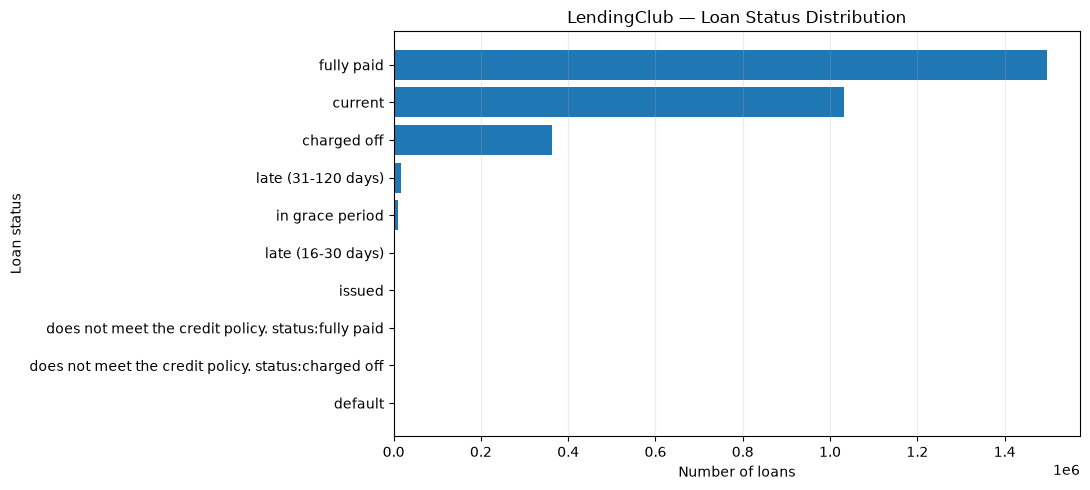

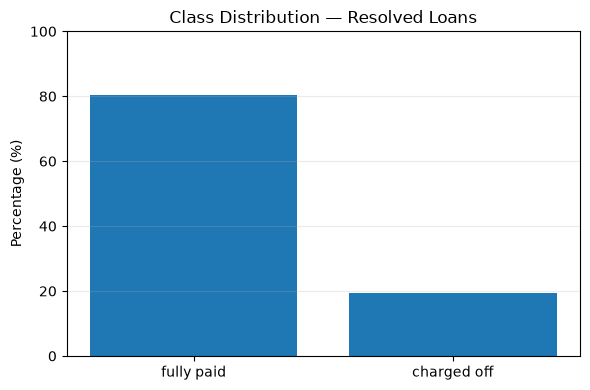


Loan-status audit saved successfully.


In [7]:
# =====================================================
# 00A.4 — Loan Status and Class Distribution
# =====================================================

import polars as pl
from IPython.display import display
import matplotlib.pyplot as plt

if "loan_status" not in columns:
    raise ValueError("loan_status column not found!")

# Normalize status labels (without changing source data)
status_lf = lf.select(
    pl.col("loan_status")
    .cast(pl.String)
    .str.strip_chars()
    .str.to_lowercase()
    .fill_null("<missing>")
    .alias("loan_status")
)

# 1. All loan statuses
status_df = (
    status_lf
    .group_by("loan_status")
    .agg(pl.len().alias("count"))
    .with_columns(
        (pl.col("count") / n_rows * 100)
        .round(2)
        .alias("percentage")
    )
    .sort("count", descending=True)
    .collect()
)

print("=" * 55)
print("ALL LOAN STATUS DISTRIBUTION")
print("=" * 55)

display(status_df)

# 2. Strict binary target candidates
target_mapping = {
    "fully paid": 0,
    "charged off": 1
}

resolved_df = (
    status_df
    .filter(
        pl.col("loan_status").is_in(
            list(target_mapping.keys())
        )
    )
    .with_columns(
        pl.col("loan_status")
        .replace_strict(target_mapping)
        .cast(pl.Int8)
        .alias("target")
    )
)

resolved_count = int(resolved_df["count"].sum())
other_count = n_rows - resolved_count

resolved_df = resolved_df.with_columns(
    (
        pl.col("count") / resolved_count * 100
        if resolved_count > 0
        else pl.lit(None)
    )
    .round(2)
    .alias("percentage_among_resolved")
)

print("\n" + "=" * 55)
print("BINARY CLASS DISTRIBUTION")
print("=" * 55)

display(resolved_df)

print(f"Total loans             : {n_rows:,}")
print(f"Strictly resolved loans : {resolved_count:,}")
print(f"Other/unresolved loans  : {other_count:,}")

print(
    f"Resolved percentage     : "
    f"{100 * resolved_count / n_rows:.2f}%"
)

# 3. Plot all status categories
fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    status_df["loan_status"].to_list()[::-1],
    status_df["count"].to_list()[::-1]
)

ax.set_title("LendingClub — Loan Status Distribution")
ax.set_xlabel("Number of loans")
ax.set_ylabel("Loan status")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# 4. Plot binary class balance
if resolved_count > 0:
    fig, ax = plt.subplots(figsize=(6, 4))

    ax.bar(
        resolved_df["loan_status"].to_list(),
        resolved_df["percentage_among_resolved"].to_list()
    )

    ax.set_title("Class Distribution — Resolved Loans")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

# 5. Save audit results
status_df.write_csv(
    audit_dir / "00_loan_status_distribution.csv"
)

resolved_df.write_csv(
    audit_dir / "00_resolved_class_distribution.csv"
)

print("\nLoan-status audit saved successfully.")

In [8]:
# =====================================================
# 00A.5 — Issue-Year, Term and Status Distribution
# =====================================================

import polars as pl
from IPython.display import display

# Handle Date/Datetime or string-formatted issue dates
issue_dtype = schema["issue_d"].base_type()

if issue_dtype in (pl.Date, pl.Datetime):
    issue_year = pl.col("issue_d").dt.year()
else:
    issue_text = pl.col("issue_d").cast(pl.String)
    issue_year = pl.coalesce(
        issue_text.str.strptime(
            pl.Date, "%Y-%m-%d", strict=False
        ),
        issue_text.str.strptime(
            pl.Date, "%b-%Y", strict=False
        )
    ).dt.year()

base_audit = lf.select(
    issue_year.alias("issue_year"),
    pl.col("term")
      .cast(pl.String)
      .str.extract(r"(\d+)", 1)
      .cast(pl.Int16, strict=False)
      .alias("term_months"),
    pl.col("loan_status")
      .cast(pl.String)
      .str.strip_chars()
      .str.to_lowercase()
      .fill_null("<missing>")
      .alias("status")
)

# Count loans by issue year, loan term, and status
year_term_status = (
    base_audit
    .group_by(["issue_year", "term_months", "status"])
    .agg(pl.len().alias("count"))
    .collect(engine="streaming")
)

# Overall loan count by issue year
year_summary = (
    year_term_status
    .group_by("issue_year")
    .agg(
        pl.col("count").sum().alias("total_loans"),
        pl.col("count")
          .filter(pl.col("status") == "fully paid")
          .sum()
          .alias("fully_paid"),
        pl.col("count")
          .filter(pl.col("status") == "charged off")
          .sum()
          .alias("charged_off")
    )
    .with_columns(
        (pl.col("fully_paid") + pl.col("charged_off"))
        .alias("resolved")
    )
    .with_columns(
        (100 * pl.col("resolved") / pl.col("total_loans"))
        .round(2)
        .alias("resolved_pct")
    )
    .sort("issue_year")
)

print("LOAN DISTRIBUTION BY ISSUE YEAR")
display(year_summary)

print("\nLOAN TERM AND STATUS DETAILS")
display(
    year_term_status.sort(
        ["issue_year", "term_months", "status"]
    )
)

year_summary.write_csv(
    audit_dir / "00_issue_year_summary.csv"
)

year_term_status.write_csv(
    audit_dir / "00_year_term_status.csv"
)

print("\nReports saved.")

LOAN DISTRIBUTION BY ISSUE YEAR


issue_year,total_loans,fully_paid,charged_off,resolved,resolved_pct
i32,u32,u32,u32,u32,f64
2007,603,206,45,251,41.63
2008,2393,1315,247,1562,65.27
2009,5281,4122,594,4716,89.3
2010,12537,10049,1487,11536,92.02
2011,21721,18424,3297,21721,100.0
…,…,…,…,…,…
2016,434407,324022,79010,403032,92.78
2017,443579,248120,66092,314212,70.84
2018,495242,149951,47123,197074,39.79



LOAN TERM AND STATUS DETAILS


issue_year,term_months,status,count
i32,i16,str,u32
2007,36,"""charged off""",45
2007,36,"""does not meet the credit polic…",113
2007,36,"""does not meet the credit polic…",239
2007,36,"""fully paid""",206
2008,36,"""charged off""",247
…,…,…,…
2020,60,"""fully paid""",1009
2020,60,"""in grace period""",237
2020,60,"""issued""",489



Reports saved.


In [11]:
# =====================================================
# 00A — Final Audit Verification
# =====================================================

import polars as pl
from IPython.display import display

# 1. Verify expected column coverage
total_features = len(columns)
missing_audited = missing_df.height
placeholder_audited = placeholder_df.height

# 2. Categorical recovery
successful_recovery = recovery_df.filter(
    pl.col("error").is_null()
    & pl.col("nulls_preserved")
    & pl.col("rows_preserved")
)

failed_recovery = recovery_df.filter(
    pl.col("error").is_not_null()
    | ~pl.col("nulls_preserved")
    | ~pl.col("rows_preserved")
)

# 3. Remaining errors
unresolved_missing = missing_df.filter(
    pl.col("audit_error").is_not_null()
)

unresolved_placeholders = placeholder_df.filter(
    pl.col("audit_error").is_not_null()
)

print("=" * 55)
print("PHASE 00A — FINAL VERIFICATION")
print("=" * 55)

print(f"Dataset rows                : {n_rows:,}")
print(f"Dataset columns             : {total_features}")
print(f"Missingness audit columns   : {missing_audited}")
print(f"Placeholder audit columns   : {placeholder_audited}")
print(f"Categorical columns tested  : {recovery_df.height}")
print(f"Successfully decoded        : {successful_recovery.height}")
print(f"Failed categorical recovery : {failed_recovery.height}")
print(f"Unresolved missingness audit: {unresolved_missing.height}")
print(f"Placeholder audit errors    : {unresolved_placeholders.height}")

print("\nFAILED CATEGORICAL COLUMNS")
display(failed_recovery)

print("\nUNRESOLVED MISSINGNESS")
display(unresolved_missing)

# 4. Decide whether the audit is sufficient
audit_passed = (
    missing_audited == total_features
    and placeholder_audited
        == len(numeric_cols) + len(categorical_cols)
    and failed_recovery.height == 0
    and unresolved_missing.height == 0
    and unresolved_placeholders.height == 0
)

print("\n" + "=" * 55)

if audit_passed:
    print("PASS — Initial audit checks completed.")
    print("Ready for Phase 00B: Feature Availability.")
else:
    print("REVIEW REQUIRED — Some audit checks remain unresolved.")

PHASE 00A — FINAL VERIFICATION
Dataset rows                : 2,925,492
Dataset columns             : 141
Missingness audit columns   : 141
Placeholder audit columns   : 132
Categorical columns tested  : 22
Successfully decoded        : 22
Failed categorical recovery : 0
Unresolved missingness audit: 0
Placeholder audit errors    : 0

FAILED CATEGORICAL COLUMNS


feature,original_dtype,decoded_dtype,original_nulls,recovered_nulls,original_rows,recovered_rows,nulls_preserved,rows_preserved,error
str,str,str,i64,i64,i64,i64,bool,bool,null



UNRESOLVED MISSINGNESS


feature,dtype,null_count,nan_count,audit_error,missing_count,missing_pct
str,str,i64,i64,str,i64,f64



PASS — Initial audit checks completed.
Ready for Phase 00B: Feature Availability.


### 00B — Feature Eligibility and Availability

In [28]:
# =====================================================
# 00B.1 — Initial Feature Registry
# =====================================================

import polars as pl
from IPython.display import display

# Target and known post-loan information
leakage_features = {
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee",
    "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt",
    "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_low", "last_fico_range_high",
    "pymnt_plan",
    "debt_settlement_flag",
    "debt_settlement_flag_date",
    "settlement_status", "settlement_date",
    "settlement_amount", "settlement_percentage",
    "settlement_term",
}

# Identifiers: retain for data lineage, not prediction
identifier_features = {
    "id", "member_id", "url", "Unnamed: 0"
}

# Lender-assigned information
lender_features = {
    "grade", "sub_grade",
    "int_rate", "installment",
    "funded_amnt", "funded_amnt_inv"
}

def classify_feature(col):
    """Assign a provisional feature-review category."""

    if col == "loan_status":
        return "TARGET_ONLY"

    if (
        col in leakage_features
        or col.startswith("hardship_")
    ):
        return "EXCLUDE_LEAKAGE"

    if col in identifier_features:
        return "IDENTIFIER"

    if col == "issue_d":
        return "SPLIT_METADATA"

    if col in lender_features:
        return "LENDER_SCENARIO_REVIEW"

    if (
        col.startswith("sec_app_")
        or col in {
            "application_type",
            "annual_inc_joint",
            "dti_joint",
            "verification_status_joint"
        }
    ):
        return "JOINT_APPLICATION_REVIEW"

    return "CANDIDATE_REVIEW"


registry = pl.DataFrame({
    "feature": columns,
    "initial_category": [
        classify_feature(c) for c in columns
    ],
    "review_status": ["PENDING"] * len(columns)
})

# Attach verified missingness statistics
registry = registry.join(
    missing_df.select(
        "feature",
        "null_count",
        "nan_count",
        "missing_pct"
    ),
    on="feature",
    how="left"
)

# Attach placeholder statistics
registry = registry.join(
    placeholder_df.select(
        "feature",
        "minus_one_count",
        "minus_one_pct"
    ),
    on="feature",
    how="left"
)

# Attach data types
registry = registry.join(
    schema_df,
    on="feature",
    how="left"
)

print("TOTAL FEATURES:", registry.height)

print("\nINITIAL FEATURE GROUPS")
display(
    registry.group_by("initial_category")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
)
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(9)
print("\nFEATURE REGISTRY")
display(
    registry.sort("initial_category", "feature")
)

registry.write_csv(
    audit_dir / "00_feature_registry_draft.csv"
)

print("\nInitial feature registry saved.")

TOTAL FEATURES: 141

INITIAL FEATURE GROUPS


initial_category,count
str,u32
"""CANDIDATE_REVIEW""",87
"""EXCLUDE_LEAKAGE""",29
"""JOINT_APPLICATION_REVIEW""",15
"""LENDER_SCENARIO_REVIEW""",6
"""IDENTIFIER""",2
"""SPLIT_METADATA""",1
"""TARGET_ONLY""",1



FEATURE REGISTRY


feature,initial_category,review_status,null_count,nan_count,missing_pct,minus_one_count,minus_one_pct,dtype
str,str,str,i64,i64,f64,i64,f64,str
"""acc_now_delinq""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,29,0.0,"""Int16"""
"""acc_open_past_24mths""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,50030,1.71,"""Int16"""
"""addr_state""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,0,0.0,"""Categorical"""
"""all_util""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,866485,29.62,"""Int16"""
"""annual_inc""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,4,0.0,"""Float32"""
"""avg_cur_bal""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,70388,2.41,"""Int64"""
"""bc_open_to_buy""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,82668,2.83,"""Int64"""
"""bc_util""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,84141,2.88,"""Float32"""
"""chargeoff_within_12_mths""","""CANDIDATE_REVIEW""","""PENDING""",0,0,0.0,145,0.0,"""Int16"""



Initial feature registry saved.


In [25]:
# =====================================================
# 00B.2 — Feature Availability by Issue Year
# =====================================================

import polars as pl
from IPython.display import display

# Features previously found to contain possible -1 placeholders
features = [
    "bc_util",
    "mort_acc",
    "tot_cur_bal",
    "pct_tl_nvr_dlq",
    "avg_cur_bal",
    "open_acc_6m",
    "inq_last_12m",
    "all_util",
    "il_util",
    "mths_since_last_delinq",
    "mths_since_last_record",
    "dti_joint",
]

features = [c for c in features if c in columns]

# The current Feather file has a Date issue_d column
base = lf.with_columns(
    pl.col("issue_d").dt.year().alias("issue_year")
)

# Approximate usable coverage:
# non-null and not equal to -1
expressions = [pl.len().alias("loans")]

for col in features:
    valid = (
        pl.col(col).is_not_null()
        & (pl.col(col) != -1).fill_null(False)
    )

    expressions.append(
        (valid.cast(pl.Float64).mean() * 100)
        .round(2)
        .alias(col)
    )

availability_df = (
    base.group_by("issue_year")
    .agg(expressions)
    .sort("issue_year")
    .collect()
)
pl.Config.set_tbl_rows(30)
print("FEATURE AVAILABILITY (%) BY ISSUE YEAR")
display(availability_df)

availability_df.write_csv(
    audit_dir / "00_feature_availability_by_year.csv"
)

print("Saved successfully.")

FEATURE AVAILABILITY (%) BY ISSUE YEAR


issue_year,loans,bc_util,mort_acc,tot_cur_bal,pct_tl_nvr_dlq,avg_cur_bal,open_acc_6m,inq_last_12m,all_util,il_util,mths_since_last_delinq,mths_since_last_record,dti_joint
i32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2007,603,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,93.53,93.03,0.0
2008,2393,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,61.93,39.36,0.0
2009,5281,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.04,4.79,0.0
2010,12537,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35.72,6.0,0.0
2011,21721,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.79,5.26,0.0
2012,53367,84.92,85.96,48.02,48.02,48.02,0.0,0.0,0.0,0.0,41.16,2.76,0.0
2013,134814,99.21,100.0,100.0,99.89,100.0,0.0,0.0,0.0,0.0,43.5,11.87,0.0
2014,235629,98.89,100.0,100.0,100.0,100.0,0.0,0.0,0.0,0.0,50.82,17.62,0.0
2015,421095,99.0,100.0,100.0,100.0,100.0,5.08,5.08,5.08,4.42,51.56,17.67,0.12


Saved successfully.


In [22]:
# =====================================================
# 00C.1 — Candidate Cohort: 36-Month Loans
# =====================================================

cohort_df = (
    year_term_status
    .filter(pl.col("term_months") == 36)
    .group_by("issue_year")
    .agg(
        pl.col("count").sum().alias("total"),

        pl.col("count")
        .filter(pl.col("status") == "fully paid")
        .sum().alias("fully_paid"),

        pl.col("count")
        .filter(pl.col("status") == "charged off")
        .sum().alias("charged_off")
    )
    .with_columns(
        (pl.col("fully_paid") + pl.col("charged_off"))
        .alias("resolved")
    )
    .with_columns(
        (100 * pl.col("resolved") / pl.col("total"))
        .round(2).alias("resolved_pct"),

        (100 * pl.col("charged_off") / pl.col("resolved"))
        .round(2).alias("charged_off_pct")
    )
    .sort("issue_year")
)
pl.Config.set_tbl_rows(30)
display(cohort_df)

cohort_df.write_csv(
    audit_dir / "00_cohort_36_month_summary.csv"
)

issue_year,total,fully_paid,charged_off,resolved,resolved_pct,charged_off_pct
i32,u32,u32,u32,u32,f64,f64
2007,603,206,45,251,41.63,17.93
2008,2393,1315,247,1562,65.27,15.81
2009,5281,4122,594,4716,89.3,12.6
2010,9156,7624,842,8466,92.46,9.95
2011,14101,12602,1499,14101,100.0,10.63
2012,43470,37567,5903,43470,100.0,13.58
2013,100422,88044,12378,100422,100.0,12.33
2014,162570,140255,22315,162570,100.0,13.73
2015,283173,240995,42178,283173,100.0,14.89


In [17]:
# 00C.2 — Compare 36- and 60-month cohorts

term_comparison = (
    year_term_status
    .filter(pl.col("issue_year").is_between(2012, 2017))
    .group_by(["issue_year", "term_months"])
    .agg(
        pl.col("count").sum().alias("total"),
        pl.col("count")
        .filter(pl.col("status") == "fully paid")
        .sum().alias("fully_paid"),
        pl.col("count")
        .filter(pl.col("status") == "charged off")
        .sum().alias("charged_off")
    )
    .with_columns(
        (pl.col("fully_paid") + pl.col("charged_off"))
        .alias("resolved")
    )
    .with_columns(
        (100 * pl.col("resolved") / pl.col("total"))
        .round(2).alias("resolved_pct")
    )
    .sort(["issue_year", "term_months"])
)

pl.Config.set_tbl_rows(30)

display(term_comparison)

issue_year,term_months,total,fully_paid,charged_off,resolved,resolved_pct
i32,i16,u32,u32,u32,u32,f64
2012,36,43470,37567,5903,43470,100.0
2012,60,9897,7156,2741,9897,100.0
2013,36,100422,88044,12378,100422,100.0
2013,60,34392,25743,8649,34392,100.0
2014,36,162570,140255,22315,162570,100.0
2014,60,73059,53616,19430,73046,99.98
2015,36,283173,240995,42178,283173,100.0
2015,60,137922,82130,37516,119646,86.75
2016,36,323495,272076,51299,323375,99.96


In [24]:
# 00B — Refine feature classifications

post_loan = [
    "deferral_term",
    "payment_plan_start_date",
    "orig_projected_additional_accrued_interest"
]

joint_features = ["revol_bal_joint"]

registry = registry.with_columns(
    pl.when(pl.col("feature").is_in(post_loan))
    .then(pl.lit("EXCLUDE_LEAKAGE"))
    .when(pl.col("feature").is_in(joint_features))
    .then(pl.lit("JOINT_APPLICATION_REVIEW"))
    .otherwise(pl.col("initial_category"))
    .alias("initial_category")
)

print("FEATURE GROUP SUMMARY")
display(
    registry.group_by("initial_category")
    .len()
    .sort("len", descending=True)
)
pl.Config.set_tbl_rows(90)
print("\nPOTENTIAL PREDICTORS")
display(
    registry.filter(
        pl.col("initial_category") == "CANDIDATE_REVIEW"
    ).select("feature", "dtype", "missing_pct", "minus_one_pct")
)

registry.write_csv(
    audit_dir / "00_feature_registry_draft.csv"
)

FEATURE GROUP SUMMARY


initial_category,len
str,u32
"""CANDIDATE_REVIEW""",83
"""EXCLUDE_LEAKAGE""",32
"""JOINT_APPLICATION_REVIEW""",16
"""LENDER_SCENARIO_REVIEW""",6
"""IDENTIFIER""",2
"""SPLIT_METADATA""",1
"""TARGET_ONLY""",1



POTENTIAL PREDICTORS


feature,dtype,missing_pct,minus_one_pct
str,str,f64,f64
"""loan_amnt""","""Int32""",0.0,0.0
"""term""","""Int16""",0.0,0.0
"""emp_title""","""Categorical""",9.0271,0.0
"""emp_length""","""Categorical""",7.0149,0.0
"""home_ownership""","""Categorical""",0.0,0.0
"""annual_inc""","""Float32""",0.0,0.0
"""verification_status""","""Categorical""",0.0,0.0
"""purpose""","""Categorical""",0.0,0.0
"""title""","""Categorical""",0.7973,0.0
